In [104]:
import numpy as np
import pandas as pd
import matplotlib.pylab as plt
import seaborn as sns

plt.style.use('ggplot')

pd.set_option('display.max_columns', 200)

In [105]:
df = pd.read_csv('Student_Depression_Dataset-selected-columns.csv')
df

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition
0,Female,22,Middle class,Single,Unmarried,Bachelor,8,3.43,Yes,Critical
1,Male,19,Middle class,Single,Unmarried,Bachelor,2,3.70,Yes,Abnormal
2,Male,23,Middle class,Single,Unmarried,Family,8,3.28,No,Abnormal
3,Male,20,Middle class,Complicated,Unmarried,Family,2,3.77,No,Good
4,Female,21,Middle class,Single,Unmarried,Family,1,4.00,No,Abnormal
...,...,...,...,...,...,...,...,...,...,...
4459,Female,26,Middle class,In a Relationship,Separated,Family,11,2.97,No,Critical
4460,Male,28,Lower Middle class,Single,Unmarried,Family,8,2.60,No,Normal
4461,Female,23,Middle class,In a Relationship,Married,Bachelor,10,2.80,No,Good
4462,Female,23,Middle class,Complicated,Married,Family,5,3.00,Yes,Normal


In [106]:
df.columns

Index(['Gender', 'Age', 'Family_background', 'Relationship_status',
       'Marital_status', 'Living_style', 'Current_semester', 'CGPA',
       'friend_circle', 'Health_condition'],
      dtype='str')

In [107]:
df = df.drop(['Current_semester'], axis = 1)

In [108]:
x = df[['Gender', 'Age', 'Family_background', 'Relationship_status',
       'Marital_status', 'Living_style', 'CGPA',
       'friend_circle']]
y = df['Health_condition']

In [109]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [110]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4464 entries, 0 to 4463
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Gender               4464 non-null   str    
 1   Age                  4464 non-null   int64  
 2   Family_background    4464 non-null   str    
 3   Relationship_status  4464 non-null   str    
 4   Marital_status       4464 non-null   str    
 5   Living_style         4464 non-null   str    
 6   CGPA                 4464 non-null   float64
 7   friend_circle        4464 non-null   str    
 8   Health_condition     4464 non-null   str    
dtypes: float64(1), int64(1), str(7)
memory usage: 314.0 KB


In [111]:
X_train

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,CGPA,friend_circle
3918,Male,20,Middle class,Single,Married,Bachelor,3.00,Yes
2807,Female,23,Middle class,Single,Unmarried,Family,3.39,Yes
1406,Male,22,Lower Middle class,Single,Unmarried,Family,3.58,Yes
3154,Female,24,Lower Middle class,Single,Unmarried,Family,3.84,Yes
2598,Female,22,Middle class,In a Relationship,Married,Family,4.00,Yes
...,...,...,...,...,...,...,...,...
4426,Female,27,Lower Middle class,Single,Married,Family,3.54,No
466,Male,24,Middle class,Single,Unmarried,Bachelor,3.67,Yes
3092,Male,26,Rich class,Single,Unmarried,Family,2.89,Yes
3772,Female,22,Middle class,In a Relationship,Unmarried,Bachelor,3.56,Yes


In [112]:
display(df.describe(include='all').T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Gender,4464,2,Female,2462,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,4464.0,NaN,NaN,NaN,22.619176,2.02298,17.0,21.0,23.0,24.0,28.0
Family_background,4464,3,Middle class,2642,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Relationship_status,4464,3,Single,2803,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Marital_status,4464,3,Unmarried,3619,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Living_style,4464,2,Bachelor,2449,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CGPA,4464.0,NaN,NaN,NaN,3.412753,0.385605,2.25,3.15,3.49,3.7,4.0
friend_circle,4464,2,Yes,3215,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Health_condition,4464,4,Normal,1787,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [113]:
df.query('CGPA > 3.50')

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,CGPA,friend_circle,Health_condition
1,Male,19,Middle class,Single,Unmarried,Bachelor,3.70,Yes,Abnormal
3,Male,20,Middle class,Complicated,Unmarried,Family,3.77,No,Good
4,Female,21,Middle class,Single,Unmarried,Family,4.00,No,Abnormal
5,Female,24,Middle class,Single,Unmarried,Bachelor,3.80,Yes,Normal
15,Female,22,Middle class,Single,Unmarried,Bachelor,3.66,Yes,Normal
...,...,...,...,...,...,...,...,...,...
4449,Female,21,Middle class,Single,Separated,Bachelor,3.86,Yes,Normal
4450,Female,28,Middle class,Single,Separated,Bachelor,3.82,No,Normal
4452,Female,21,Rich class,In a Relationship,Separated,Family,3.85,No,Abnormal
4456,Female,25,Middle class,Single,Unmarried,Family,3.69,Yes,Critical


<Axes: xlabel='Age'>

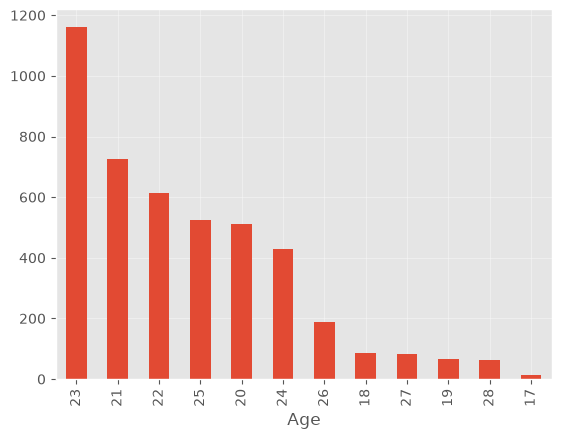

In [114]:
df['Age'].value_counts().plot(kind='bar')

<Axes: title={'center': 'CGPA'}, ylabel='Density'>

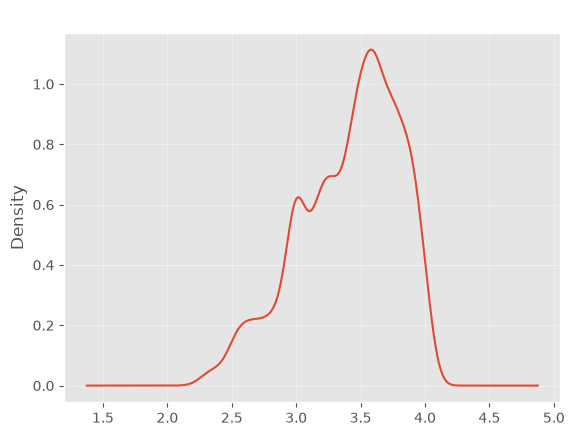

In [115]:
df['CGPA'].plot(kind='kde',
                title='CGPA')

In [116]:
cat_cols = df.select_dtypes(include='str').columns

for col in cat_cols:
    print(f"\n Column: {col}")
    counts = df[col].value_counts()

    percentages = df[col].value_counts(normalize=True) *100

    result = pd.DataFrame({'Count': counts, 'Percentage': percentages})

    display(result)


 Column: Gender


,Count,Percentage
Gender,,
Female,2462,55.15233
Male,2002,44.84767



 Column: Family_background


,Count,Percentage
Family_background,,
Middle class,2642,59.184588
Lower Middle class,1151,25.784050
Rich class,671,15.031362



 Column: Relationship_status


,Count,Percentage
Relationship_status,,
Single,2803,62.791219
In a Relationship,1457,32.638889
Complicated,204,4.569892


... (4 outputs left out)


 Column: friend_circle


,Count,Percentage
friend_circle,,
Yes,3215,72.020609
No,1249,27.979391



 Column: Health_condition


,Count,Percentage
Health_condition,,
Normal,1787,40.031362
Good,1162,26.030466
Abnormal,881,19.735663
Critical,634,14.202509


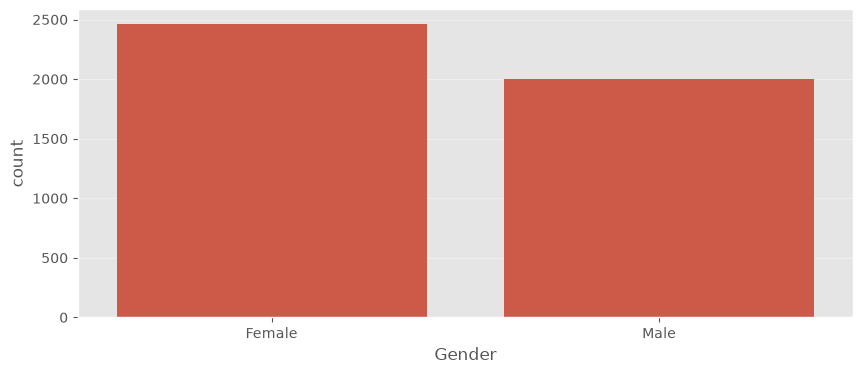

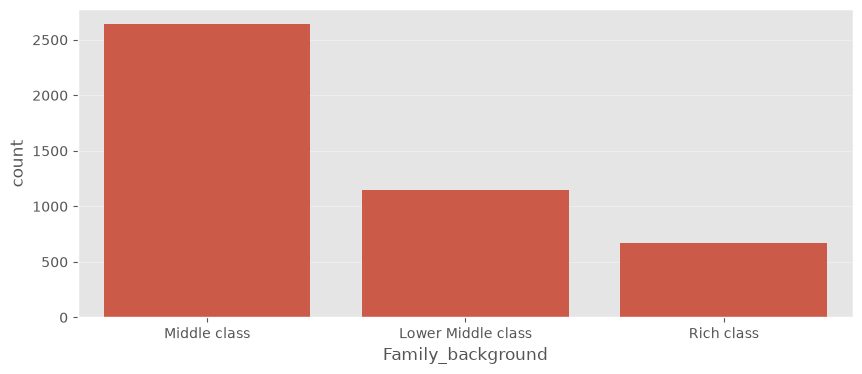

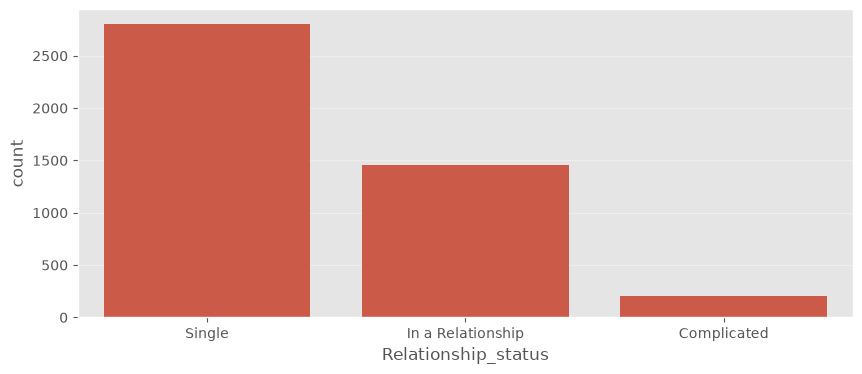

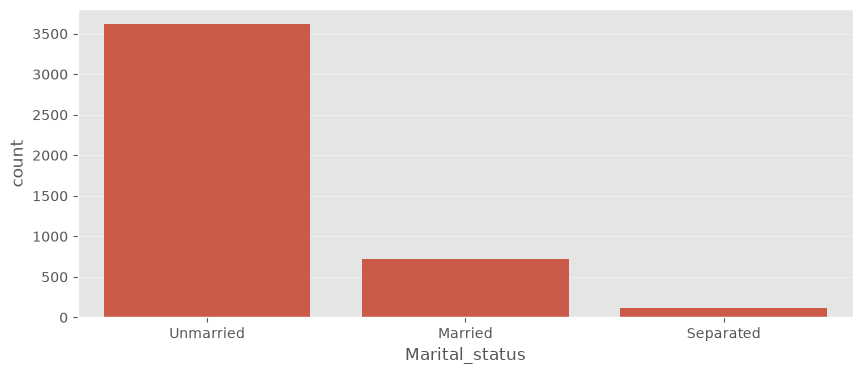

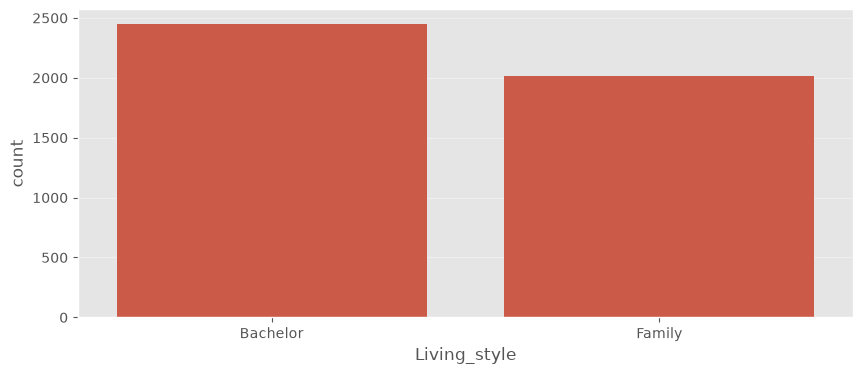

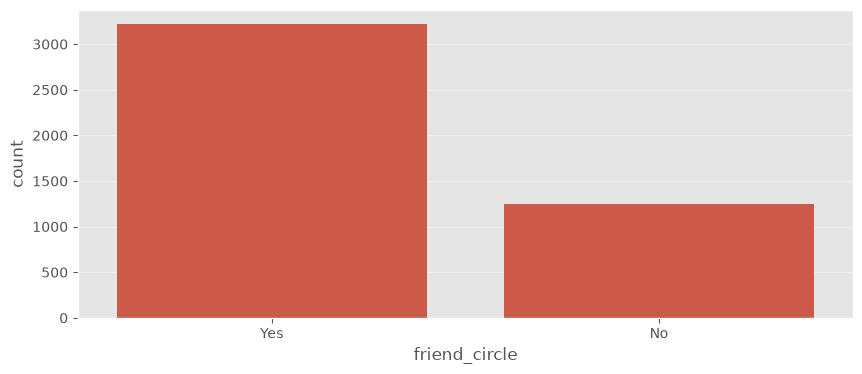

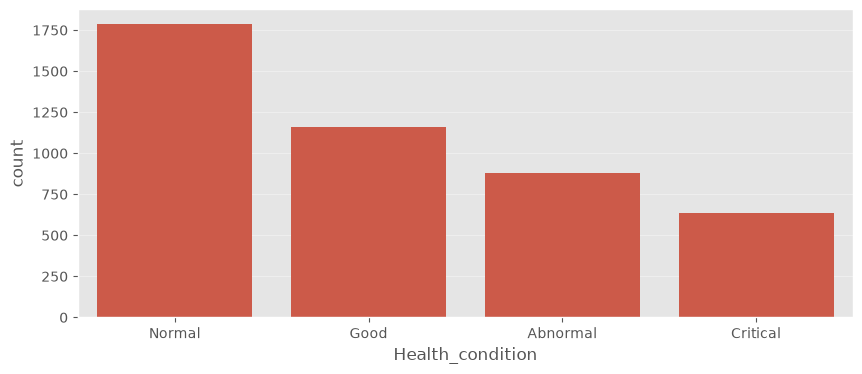

In [117]:
for col in cat_cols:
    plt.figure(figsize=(10, 4))

    sns.countplot(
        data = df,
        x = col,
        order=df[col].value_counts().index,
    )

In [118]:
num_cols = df.select_dtypes(include='number').columns
display(df[num_cols].describe(include='all').T)

,count,mean,std,min,25%,50%,75%,max
Age,4464.0,22.619176,2.022980,17.00,21.00,23.00,24.0,28.0
CGPA,4464.0,3.412753,0.385605,2.25,3.15,3.49,3.7,4.0



 Column : Age

 Column : CGPA


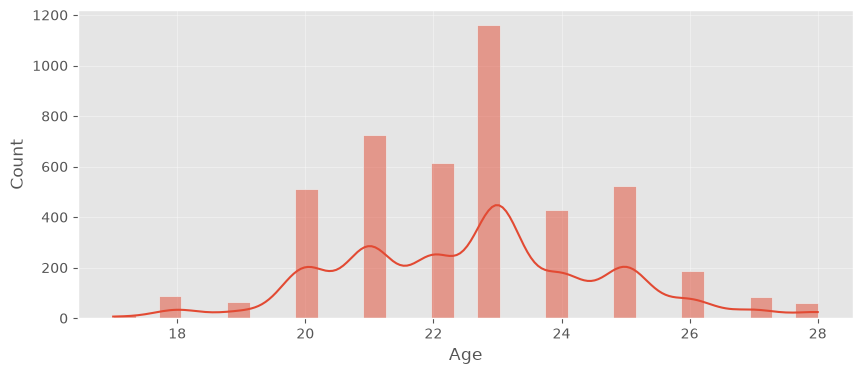

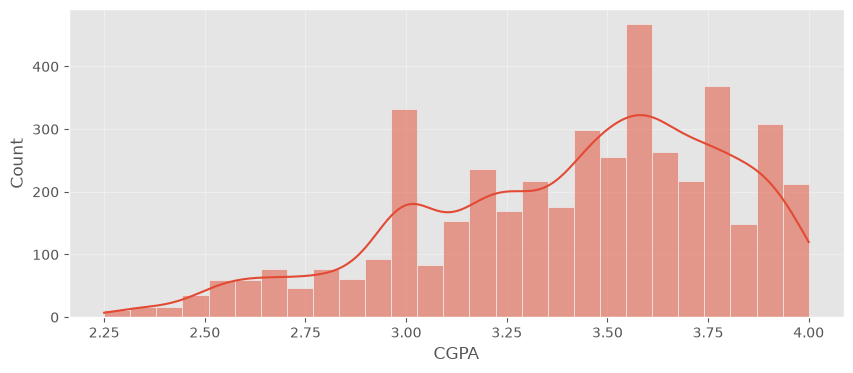

In [119]:
for col in num_cols:
    print(f"\n Column : {col}")
    plt.figure(figsize=(10,4))

    sns.histplot(
        data=df,
        x=col,
        kde=True
    )

In [120]:
df

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,CGPA,friend_circle,Health_condition
0,Female,22,Middle class,Single,Unmarried,Bachelor,3.43,Yes,Critical
1,Male,19,Middle class,Single,Unmarried,Bachelor,3.70,Yes,Abnormal
2,Male,23,Middle class,Single,Unmarried,Family,3.28,No,Abnormal
3,Male,20,Middle class,Complicated,Unmarried,Family,3.77,No,Good
4,Female,21,Middle class,Single,Unmarried,Family,4.00,No,Abnormal
...,...,...,...,...,...,...,...,...,...
4459,Female,26,Middle class,In a Relationship,Separated,Family,2.97,No,Critical
4460,Male,28,Lower Middle class,Single,Unmarried,Family,2.60,No,Normal
4461,Female,23,Middle class,In a Relationship,Married,Bachelor,2.80,No,Good
4462,Female,23,Middle class,Complicated,Married,Family,3.00,Yes,Normal


In [121]:
# from sklearn.preprocessing import LabelEncoder
#
# le = LabelEncoder()
#
# df['Marital_status_encoded'] = le.fit_transform(df['Marital_status'])
# df['Health_condition_encoded'] = le.fit_transform(df['Health_condition'])
# df['Relationship_status_encoded'] = le.fit_transform(df['Relationship_status'])
# df

### Better to use onehot encoding


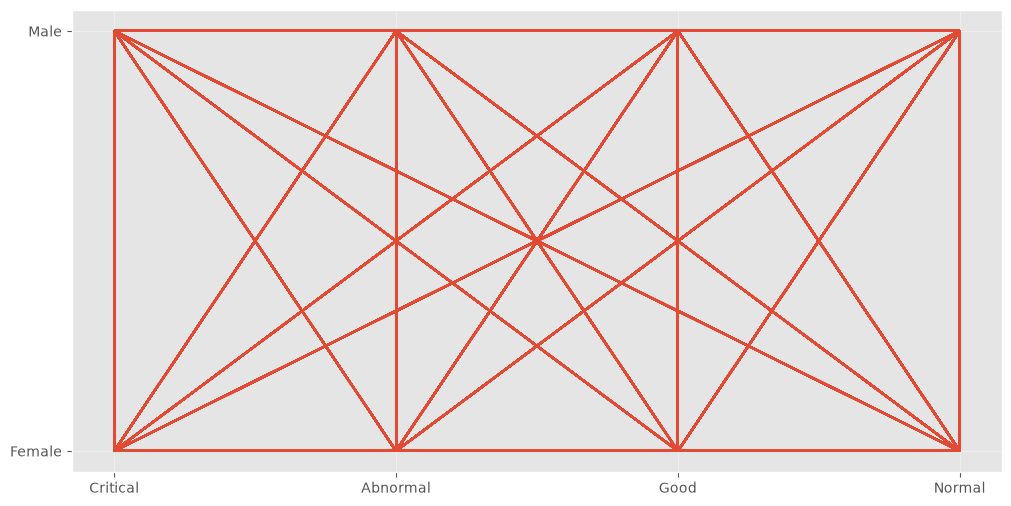

In [122]:
x = df['Health_condition']
y = df['Gender']
plt.figure(figsize=(12, 6))
# plt.hist(x)
plt.plot(x, y)
# plt.hist(y)

(array([ 100.,   65.,  513.,  726.,  614., 1161.,  430.,  523.,  187.,
         145.]),
 array([17. , 18.1, 19.2, 20.3, 21.4, 22.5, 23.6, 24.7, 25.8, 26.9, 28. ]),
 <BarContainer object of 10 artists>)

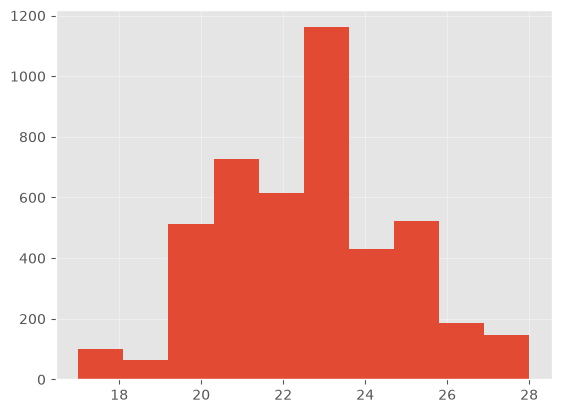

In [123]:
plt.hist(df['Age'])

In [124]:
df.columns

Index(['Gender', 'Age', 'Family_background', 'Relationship_status',
       'Marital_status', 'Living_style', 'CGPA', 'friend_circle',
       'Health_condition'],
      dtype='str')

In [125]:
from sklearn.preprocessing import OneHotEncoder

categorical_cols = [
    'Gender',
    'Relationship_status',
       'Marital_status', 'Living_style', 'friend_circle'

]

onehot = OneHotEncoder(
    sparse_output=False,
    handle_unknown='ignore',
    dtype=int
)

X_train_onehot = onehot.fit_transform(X_train[categorical_cols])
X_test_onehot = onehot.transform(X_test[categorical_cols])


In [126]:
X_train_onehot

array([[0, 1, 0, ..., 0, 0, 1],
       [1, 0, 0, ..., 1, 0, 1],
       [0, 1, 0, ..., 1, 0, 1],
       ...,
       [0, 1, 0, ..., 1, 0, 1],
       [1, 0, 0, ..., 0, 0, 1],
       [0, 1, 0, ..., 0, 0, 1]], shape=(3571, 12))

In [127]:
# Convert encoded arrays into DataFrames
onehot_columns = onehot.get_feature_names_out(
    [ 'Gender',
    'Relationship_status',
       'Marital_status', 'Living_style', 'friend_circle'

    ]
)

X_train_encoded = pd.DataFrame(
    X_train_onehot,
    columns = onehot_columns,
    index=X_train.index
)

X_test_encoded = pd.DataFrame(
    X_test_onehot,
    columns = onehot_columns,
    index=X_test.index
)

In [128]:
df_ohc_wpd = pd.get_dummies(
    df,
    columns=['Gender'],
    dtype=int
)

print(df_ohc_wpd.head())

   Age Family_background Relationship_status Marital_status Living_style  \
0   22      Middle class              Single      Unmarried     Bachelor   
1   19      Middle class              Single      Unmarried     Bachelor   
2   23      Middle class              Single      Unmarried       Family   
3   20      Middle class         Complicated      Unmarried       Family   
4   21      Middle class              Single      Unmarried       Family   

   CGPA friend_circle Health_condition  Gender_Female  Gender_Male  
0  3.43           Yes         Critical              1            0  
1  3.70           Yes         Abnormal              0            1  
2  3.28            No         Abnormal              0            1  
3  3.77            No             Good              0            1  
4  4.00            No         Abnormal              1            0  


In [129]:
from sklearn.preprocessing import OrdinalEncoder

family_order = [
'Lower Middle class',
    'Middle class',
'Rich class'
]

enc = OrdinalEncoder(
    categories=[family_order]
)

X_train_ordinal = enc.fit_transform(X_train[['Family_background']])
X_test_ordinal = enc.transform(X_test[['Family_background']])


In [130]:
X_test_ordinal

array([[1.],
       [1.],
       [0.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [0.],
       [0.],
       [1.],
       [1.],
       [1.],
       [2.],
       [1.],
       [1.],
       [1.],
       [0.],
       [0.],
       [2.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [0.],
       [0.],
       [1.],
       [1.],
       [1.],
       [1.],
       [0.],
       [0.],
       [1.],
       [0.],
       [1.],
       [1.],
       [0.],
       [0.],
       [1.],
       [2.],
       [1.],
       [1.],
       [0.],
       [1.],
       [0.],
       [1.],
       [0.],
       [1.],
       [1.],
       [2.],
       [1.],
       [0.],
       [1.],
       [0.],
       [1.],
       [1.],
       [0.],
       [1.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [0.],
       [1.],
       [2.],
       [0.],
       [0.],

In [131]:
X_train_encoded["Family_background"] = X_train_ordinal
X_test_encoded['Family_background'] = X_test_ordinal

In [132]:
X_train_encoded

,Gender_Female,Gender_Male,Relationship_status_Complicated,Relationship_status_In a Relationship,Relationship_status_Single,Marital_status_Married,Marital_status_Separated,Marital_status_Unmarried,Living_style_Bachelor,Living_style_Family,friend_circle_No,friend_circle_Yes,Family_background
3918,0,1,0,0,1,1,0,0,1,0,0,1,1.0
2807,1,0,0,0,1,0,0,1,0,1,0,1,1.0
1406,0,1,0,0,1,0,0,1,0,1,0,1,0.0
3154,1,0,0,0,1,0,0,1,0,1,0,1,0.0
2598,1,0,0,1,0,1,0,0,0,1,0,1,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4426,1,0,0,0,1,1,0,0,0,1,1,0,0.0
466,0,1,0,0,1,0,0,1,1,0,0,1,1.0
3092,0,1,0,0,1,0,0,1,0,1,0,1,2.0
3772,1,0,0,1,0,0,0,1,1,0,0,1,1.0


In [133]:
cat_cols

Index(['Gender', 'Family_background', 'Relationship_status', 'Marital_status',
       'Living_style', 'friend_circle', 'Health_condition'],
      dtype='str')

In [134]:
# Splitting numerical columns

X_train_num = X_train.drop(columns= ['Gender', 'Family_background', 'Relationship_status', 'Marital_status',
       'Living_style', 'friend_circle'])
X_test_num = X_test.drop(columns=['Gender', 'Family_background', 'Relationship_status', 'Marital_status',
       'Living_style', 'friend_circle'])

# remember to exclude the prediction column or y_test column

In [145]:
X_train_final = pd.concat([X_train_num, X_train_encoded], axis = 1).sort_index()
X_test_final = pd.concat([X_test_num, X_test_encoded], axis = 1).sort_index()

In [188]:
X_train_final.head(10)

,Age,CGPA,Gender_Female,Gender_Male,Relationship_status_Complicated,Relationship_status_In a Relationship,Relationship_status_Single,Marital_status_Married,Marital_status_Separated,Marital_status_Unmarried,Living_style_Bachelor,Living_style_Family,friend_circle_No,friend_circle_Yes,Family_background
0,22,3.43,1,0,0,0,1,0,0,1,1,0,0,1,1.0
1,19,3.70,0,1,0,0,1,0,0,1,1,0,0,1,1.0
2,23,3.28,0,1,0,0,1,0,0,1,0,1,1,0,1.0
3,20,3.77,0,1,1,0,0,0,0,1,0,1,1,0,1.0
4,21,4.00,1,0,0,0,1,0,0,1,0,1,1,0,1.0
5,24,3.80,1,0,0,0,1,0,0,1,1,0,0,1,1.0
6,21,3.50,1,0,0,0,1,0,0,1,0,1,0,1,0.0
7,19,2.71,1,0,0,0,1,0,0,1,0,1,0,1,1.0
9,22,3.34,1,0,0,1,0,1,0,0,0,1,0,1,1.0
10,23,2.89,1,0,0,0,1,0,0,1,1,0,1,0,1.0


In [178]:
print(X_train_final.shape)
print(X_test_final.shape)

print(y_train.shape)
print(y_test.shape)

(3571, 15)
(893, 15)
(3571,)
(893,)


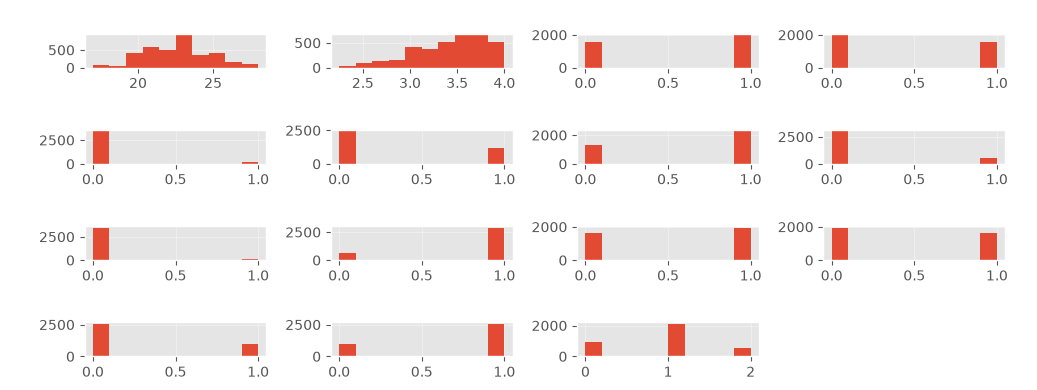

In [148]:
X_train_final.hist(figsize=(10, 4))
plt.tight_layout()
plt.show()

In [150]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, f1_score, confusion_matrix, classification_report, ConfusionMatrixDisplay, recall_score

knn = KNeighborsClassifier()

knn.fit(X_train_final, y_train)
y_pred = knn.predict(X_test_final)


In [165]:
cm = confusion_matrix(y_test, y_pred)
print(cm)

[[ 40  25  31  62]
 [ 35  16  30  51]
 [ 49  21  76  96]
 [ 77  33 104 147]]


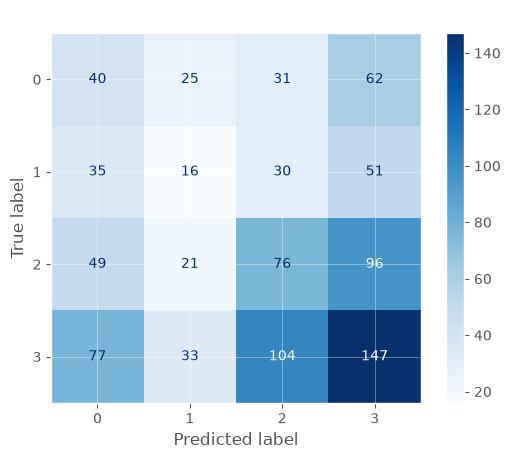

In [166]:
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap='Blues')
plt.title('Confusion Matrix (Iris)')
plt.show()

In [169]:
print(precision_score(y_test, y_pred, average=None)) # returns 4 values for 4 classes
print(recall_score(y_test, y_pred, average=None))
print(accuracy_score(y_test, y_pred))
print(f1_score(y_test, y_pred, average=None))

## All in one
print(classification_report(y_test, y_pred))


[0.19900498 0.16842105 0.3153527  0.41292135]
[0.25316456 0.12121212 0.31404959 0.40720222]
0.3124300111982083
[0.22284123 0.14096916 0.31469979 0.41004184]
              precision    recall  f1-score   support

    Abnormal       0.20      0.25      0.22       158
    Critical       0.17      0.12      0.14       132
        Good       0.32      0.31      0.31       242
      Normal       0.41      0.41      0.41       361

    accuracy                           0.31       893
   macro avg       0.27      0.27      0.27       893
weighted avg       0.31      0.31      0.31       893



In [176]:
X_test_final

,Age,CGPA,Gender_Female,Gender_Male,Relationship_status_Complicated,Relationship_status_In a Relationship,Relationship_status_Single,Marital_status_Married,Marital_status_Separated,Marital_status_Unmarried,Living_style_Bachelor,Living_style_Family,friend_circle_No,friend_circle_Yes,Family_background
8,21,3.10,1,0,0,0,1,0,0,1,0,1,0,1,1.0
14,24,3.00,0,1,0,0,1,0,0,1,1,0,0,1,1.0
17,24,3.15,1,0,0,0,1,0,0,1,0,1,0,1,1.0
19,23,3.80,0,1,0,0,1,0,0,1,0,1,0,1,1.0
23,22,3.76,1,0,0,0,1,0,0,1,1,0,0,1,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4441,22,3.80,0,1,0,0,1,1,0,0,1,0,1,0,0.0
4447,24,2.66,1,0,0,0,1,0,1,0,1,0,0,1,0.0
4449,21,3.86,1,0,0,0,1,0,1,0,1,0,0,1,1.0
4457,27,3.56,1,0,0,1,0,1,0,0,1,0,0,1,1.0


In [184]:
single_instance = X_test_final.iloc[[8]]

prediction = knn.predict(single_instance)
print(prediction)

print(y_test[8])

['Normal']
Abnormal


In [183]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

lr = LogisticRegression(max_iter=1000)

lr.fit(X_train_final, y_train)

y_pred = lr.predict(X_test_final)

print(accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

0.40425531914893614
              precision    recall  f1-score   support

    Abnormal       0.00      0.00      0.00       158
    Critical       0.00      0.00      0.00       132
        Good       0.00      0.00      0.00       242
      Normal       0.40      1.00      0.58       361

    accuracy                           0.40       893
   macro avg       0.10      0.25      0.14       893
weighted avg       0.16      0.40      0.23       893

[[  0   0   0 158]
 [  0   0   0 132]
 [  0   0   0 242]
 [  0   0   0 361]]


F:\Coding\python\AI-ML\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
F:\Coding\python\AI-ML\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
F:\Coding\python\AI-ML\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [199]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import confusion_matrix, classification_report

In [187]:
single_instance = X_test_final.iloc[[8]]

prediction = lr.predict(single_instance)
print(prediction)

print(y_test[8])

['Normal']
Abnormal


In [205]:
dt = DecisionTreeClassifier()
svc = SVC()
rf = RandomForestClassifier()
nb = GaussianNB()

In [207]:
dt.fit(X_train_final, y_train)
y_pred = dt.predict(X_test_final)
print(accuracy_score(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

0.2989921612541993
[[ 37  22  42  57]
 [ 34  13  30  55]
 [ 58  30  70  84]
 [ 79  58  77 147]]
              precision    recall  f1-score   support

    Abnormal       0.18      0.23      0.20       158
    Critical       0.11      0.10      0.10       132
        Good       0.32      0.29      0.30       242
      Normal       0.43      0.41      0.42       361

    accuracy                           0.30       893
   macro avg       0.26      0.26      0.26       893
weighted avg       0.31      0.30      0.30       893



In [204]:
svc.fit(X_train_final, y_train)
y_pred = svc.predict(X_test_final)
print(accuracy_score(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

0.40425531914893614
[[  0   0   0 158]
 [  0   0   0 132]
 [  0   0   0 242]
 [  0   0   0 361]]
              precision    recall  f1-score   support

    Abnormal       0.00      0.00      0.00       158
    Critical       0.00      0.00      0.00       132
        Good       0.00      0.00      0.00       242
      Normal       0.40      1.00      0.58       361

    accuracy                           0.40       893
   macro avg       0.10      0.25      0.14       893
weighted avg       0.16      0.40      0.23       893



F:\Coding\python\AI-ML\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
F:\Coding\python\AI-ML\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
F:\Coding\python\AI-ML\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [202]:
rf.fit(X_train_final, y_train)
y_pred = rf.predict(X_test_final)
print(accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

0.3068309070548712
              precision    recall  f1-score   support

    Abnormal       0.17      0.18      0.17       158
    Critical       0.13      0.09      0.11       132
        Good       0.29      0.27      0.28       242
      Normal       0.41      0.47      0.44       361

    accuracy                           0.31       893
   macro avg       0.25      0.25      0.25       893
weighted avg       0.29      0.31      0.30       893



In [203]:
nb.fit(X_train_final, y_train)
y_pred = nb.predict(X_test_final)
print(accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

0.3505039193729003
              precision    recall  f1-score   support

    Abnormal       0.13      0.04      0.07       158
    Critical       0.09      0.06      0.07       132
        Good       0.32      0.08      0.13       242
      Normal       0.40      0.77      0.53       361

    accuracy                           0.35       893
   macro avg       0.24      0.24      0.20       893
weighted avg       0.29      0.35      0.27       893

